# Normale verdeling

In de volgende functies gaan we ervan uit dat de parameters mu en sigma van de normale verdeling bekend zijn.

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import math
from scipy.stats import norm, probplot

from utils import *

## 1. Gegeven grenswaarden $a$ en $b$, bereken de kans op uitkomst tussen $a$ en $b$

In [6]:
def compute_probabilities(left=None, right=None, mu=0, sigma=1):
    # Kansberekening
    if left is not None and right is not None:
        assert left <= right
        prob = norm.cdf(right, mu, sigma) - norm.cdf(left, mu, sigma)
        print(f"P({left} <= X <= {right}) = {prob:.4f}")
        return prob
    elif left is not None:
        prob = 1 - norm.cdf(left, mu, sigma)
        print(f"P(X >= {left}) = {prob:.4f}")
        return prob
    else:
        prob = norm.cdf(right, mu, sigma)
        print(f"P(X <= {right}) = {prob:.4f}")
        return prob

compute_probabilities(left=0, right=1, mu=0, sigma=1)

P(0 <= X <= 1) = 0.3413


0.3413447460685429

## 2. Gegeven kans $p$, bereken de grenswaarden behorende bij deze kans $p$

In [8]:
def compute_boundary_values(area=0.05, mu=0, sigma=1, tail="left"):
    if tail == "left":
        g = norm.ppf(area, mu, sigma)
        print(f"P(X <= g) = {area} geeft g = {g:.4f}")
        return g
    elif tail == "center":
        g1, g2 = norm.ppf(area/2, mu, sigma), norm.ppf(1-area/2,mu,sigma)
        print(f"P(g1 <= X <= g2) = {area} geeft g1 = {g1:.4f} en g2 = {g2:.4f}")
        return g1, g2
    else:
        g = norm.ppf(1-area, mu, sigma)
        print(f"P(X >= g) = {area} geeft g = {g:.4f}")
        return g

compute_boundary_values(area=0.05, mu=0, sigma=1, tail="right")

P(X >= g) = 0.05 geeft g = 1.6449


1.6448536269514722

## 3. Gegeven een steekproefgemiddelde $\bar{x}$, standaardafwijking $\sigma$ en steekproefgrootte $n$, bereken het betrouwbaarheidsinterval

In [10]:
def compute_confidence_z_interval(data=None, sample_mean=None, n=None, sigma=1, confidence=0.05, tail="center"):
    if data is not None:
        assert isinstance(data, list)
        n = len(data)
        sample_mean = sum(data) / len(data)
    else:
        assert sample_mean is not None and n is not None
    area = 1 - confidence
    std_error = sigma / np.sqrt(n)

    text = f"\\SI{{{int(100 * area)}}}{{\\percent}}-betrouwbaarheidsinterval voor het gemiddelde $\\mu$ "
    # Kansberekening
    if tail == "left":
        g = norm.ppf(confidence, sample_mean, std_error)
        print(text + f"(linkszijdig): $[{g:.4f}, \\infty)$")
        return g
    elif tail == "center":
        g1 = norm.ppf(confidence / 2, sample_mean, std_error)
        g2 = norm.ppf(1 - confidence / 2, sample_mean, std_error)
        print(text + f"(tweezijdig): $[{g1:.4f}, {g2:.4f}]$")
        return g1, g2
    elif tail == "right":
        g = norm.ppf(1 - confidence, sample_mean, std_error)
        print(text + f"(rechtszijdig): $(-\\infty, {g:.4f}]$")
        return g

print("Exercise 8.4")
compute_confidence_z_interval(sample_mean=1000, sigma=25, n=10, confidence=0.05)
compute_confidence_z_interval(sample_mean=1000, sigma=25, n=25, confidence=0.05)
compute_confidence_z_interval(sample_mean=1000, sigma=25, n=10, confidence=0.01)
compute_confidence_z_interval(sample_mean=1000, sigma=25, n=25, confidence=0.01)

print("\nExercise 8.11:")
compute_confidence_z_interval(data=[91.6, 87.34, 90.8, 89.65, 91.3], sigma=3, confidence=0.05)

print("\n Exercise 8.29:")
compute_confidence_z_interval(sample_mean=30, sigma=0.5, n=25, confidence=0.05)

print("\n Exercise 8.29:")
compute_confidence_z_interval(sample_mean=30, sigma=0.5, n=25, confidence=0.05)

Exercise 8.4
\SI{95}{\percent}-betrouwbaarheidsinterval voor het gemiddelde $\mu$ (tweezijdig): $[984.5051, 1015.4949]$
\SI{95}{\percent}-betrouwbaarheidsinterval voor het gemiddelde $\mu$ (tweezijdig): $[990.2002, 1009.7998]$
\SI{99}{\percent}-betrouwbaarheidsinterval voor het gemiddelde $\mu$ (tweezijdig): $[979.6363, 1020.3637]$
\SI{99}{\percent}-betrouwbaarheidsinterval voor het gemiddelde $\mu$ (tweezijdig): $[987.1209, 1012.8791]$

Exercise 8.11:
\SI{95}{\percent}-betrouwbaarheidsinterval voor het gemiddelde $\mu$ (tweezijdig): $[87.5084, 92.7676]$

 Exercise 8.29:
\SI{95}{\percent}-betrouwbaarheidsinterval voor het gemiddelde $\mu$ (tweezijdig): $[29.8040, 30.1960]$

 Exercise 8.29:
\SI{95}{\percent}-betrouwbaarheidsinterval voor het gemiddelde $\mu$ (tweezijdig): $[29.8040, 30.1960]$


(29.804003601545993, 30.195996398454007)

## 4. Minimale steekproefgrootte voor een betrouwbaarheidsinterval voor het gemiddelde $\mu$ met afwijking $\pm a$ ($\sigma$ bekend)

In [12]:
def minimum_sample_size(confidence=0.05, std=1, margin=1, whole_interval=False):
    if whole_interval:
        margin = margin / 2
    z = norm.ppf(q=1-confidence/2, loc=0, scale=1)
    n = ((z * std) / (margin)) ** 2
    print(f"Minimale steekproefgrootte $n = \\left(\\frac{{z_{{\\alpha/2}} \\cdot \\sigma}}{{a}}\\right)^2 = {n:.4f}$")

minimum_sample_size(confidence=0.05, std=25, margin=30, whole_interval=True)
minimum_sample_size(confidence=0.01, std=25, margin=30, whole_interval=True)
minimum_sample_size(confidence=0.05, std=75.2, margin=10, whole_interval=False)


Minimale steekproefgrootte $n = \left(\frac{z_{\alpha/2} \cdot \sigma}{a}\right)^2 = 10.6707$
Minimale steekproefgrootte $n = \left(\frac{z_{\alpha/2} \cdot \sigma}{a}\right)^2 = 18.4303$
Minimale steekproefgrootte $n = \left(\frac{z_{\alpha/2} \cdot \sigma}{a}\right)^2 = 217.2360$


## 5. QQ-normality plots

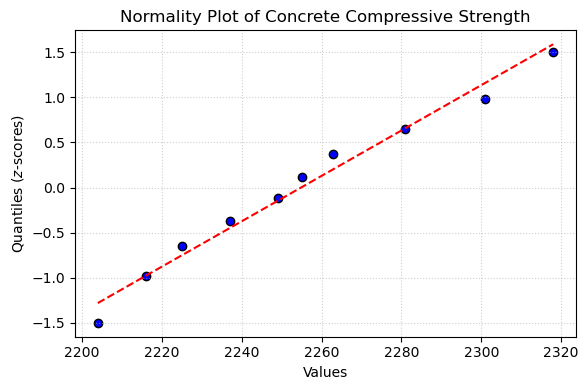

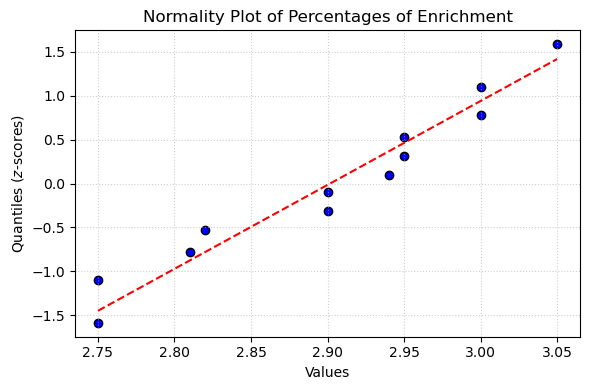

In [14]:
def draw_qq_normality_plot(data, title):
    (z_scores, values), (slope, intercept, _) = probplot(data, dist="norm")

    # Create plot with values on X and z-scores on Y
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.scatter(values, z_scores, color="blue", edgecolors="k", label="Data Points")
    
    # Recalculate reference line equation for inverted axes
    fit_line_y = (values - intercept) / slope
    ax.plot(values, fit_line_y, color="red", linestyle="--", label="Fit Line")
    
    ax.set_xlabel("Values")
    ax.set_ylabel("Quantiles ($z$-scores)")
    ax.set_title(title)
    ax.grid(True, linestyle=":", alpha=0.6)
    # ax.legend()
    
    plt.tight_layout()
    plt.show()

data = [2216, 2237, 2249, 2204, 2225, 2301, 2281, 2263, 2318, 2255]
draw_qq_normality_plot(data, "Normality Plot of Concrete Compressive Strength")

data = [2.94, 3.00, 2.90, 2.75, 3.00, 2.95, 2.90, 2.75, 2.95, 2.82, 2.81, 3.05]
draw_qq_normality_plot(data, "Normality Plot of Percentages of Enrichment")

## 6. Visualiseer normalcdf

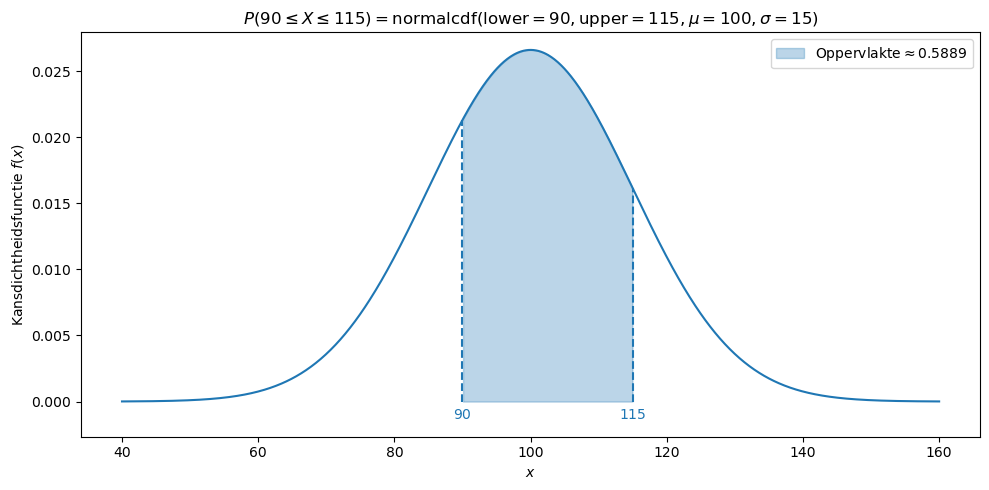

In [16]:
# Normale verdeling
def draw_normal_probabilities(mu=0, sigma=1, left=-math.inf, right=math.inf, width=8, height=5, filename=None):
    shift = 0.05
    variable_name = "Z" if mu == 0 and sigma == 1 else "X"
    x = np.linspace(mu - 4*sigma, mu + 4*sigma, 1_000)
    y = norm.pdf(x, mu, sigma)

    # Kansberekening
    if left and right:
        assert left <= right
        prob = pretty_print(norm.cdf(right, mu, sigma) - norm.cdf(left, mu, sigma))
        mask = ((x >= left) & (x <= right))
        label = f"$\\text{{Oppervlakte}} \\approx {prob}$"#f"$P({left} \\leq {variable_name} \\leq {right}) \\approx {prob}$" 
    elif left:
        prob = pretty_print(1 - norm.cdf(left, mu, sigma))
        mask = (x >= left)
        label = f"$\\text{{Oppervlakte}} \\approx {prob}$"
    else:
        prob = pretty_print(norm.cdf(right, mu, sigma))
        mask = (x <= right)
        label = f"$\\text{{Oppervlakte}} \\approx {prob}$"# f"$P({variable_name} \\leq {right}) \\approx {prob}$"

    # Plot
    fig, ax = plt.subplots(figsize=(width, height))
    ax.plot(x, y, color=primary_plot_color)
    ax.fill_between(x, y, where=mask, color=primary_plot_color, alpha=opacity_level, label=label)
    if left > -math.inf:
        ax.plot([left, left], [0, norm.pdf(left, mu, sigma)], color=primary_plot_color, linestyle='--')
        ax.text(left, -shift * max(y), f"${left}$", ha="center", color=primary_plot_color)
    if right < math.inf:
        ax.plot([right, right], [0, norm.pdf(right, mu, sigma)], color=primary_plot_color, linestyle='--')
        ax.text(right, -shift* max(y), f"${right}$", ha="center", color=primary_plot_color)


    if mu == 0 and sigma == 1:
        left = "-10^{99}" if left == -math.inf else left
        right = "10^{99}" if right == math.inf else right
        ax.set_title(f'$P({str(left)+" \\leq " if left != "-10^{99}" else ""}X{" \\leq " + str(right) if right != "10^{99}" else ""}) = \\text{{normalcdf}}(\\text{{lower}}={left}, \\text{{upper}}={right}, \\mu={mu}, \\sigma={sigma})$')
        ax.set_xlabel('$z$')
        ax.set_ylabel('Kansdichtheidsfunctie $f(z)$')
    else:
        ax.set_title(f'$P({str(left)+" \\leq " if left != "-10^{99}" else ""}X{" \\leq " + str(right) if right != "10^{99}" else ""}) = \\text{{normalcdf}}(\\text{{lower}}={left}, \\text{{upper}}={right}, \\mu={mu}, \\sigma={sigma})$')
        ax.set_xlabel('$x$')
        ax.set_ylabel('Kansdichtheidsfunctie $f(x)$')

    ax.set_ylim(bottom=-2*shift*max(y))
    plt.legend()
    plt.tight_layout()
    plt.savefig(filename)

# Collegevoorbeeld
draw_normal_probabilities(mu=100, sigma=15, left=90, right=115, width=10, height=5, filename="college3_voorbeeld_normalcdf.png")

## 7. Visualiseer invnorm

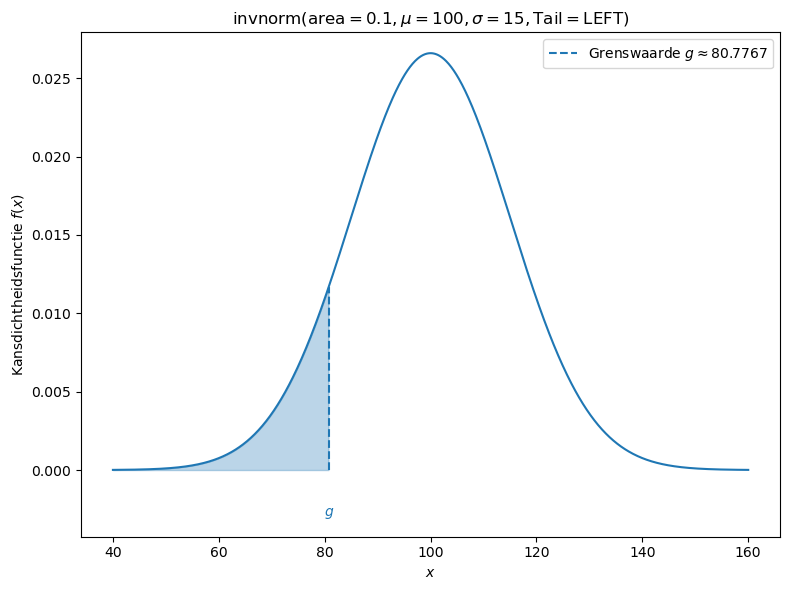

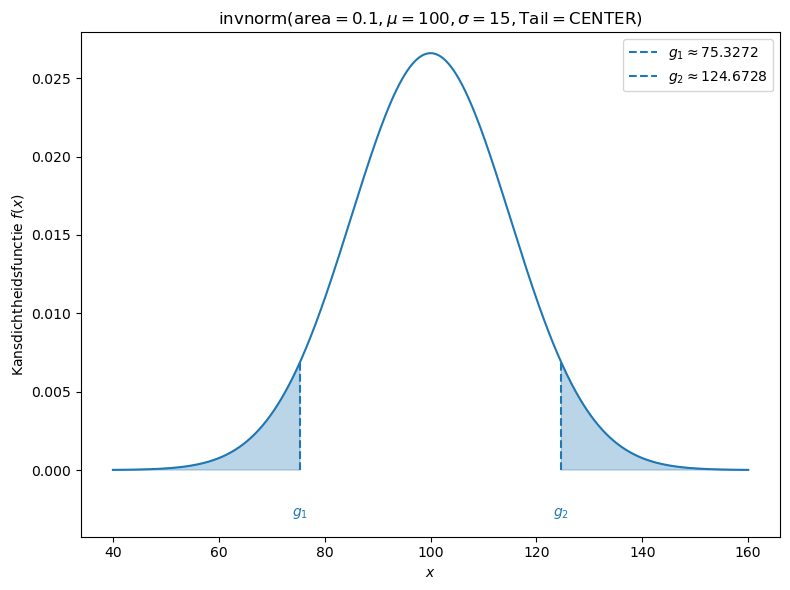

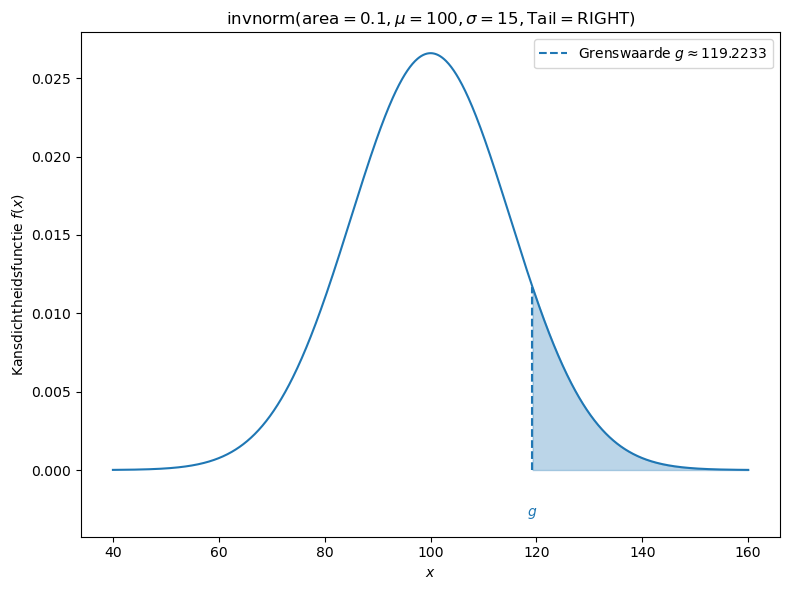

In [18]:
# Normale verdeling
def draw_boundary_values(mu=0, sigma=1, prob=0.5, tail="left", filename=None):
    variable_name = "Z" if mu == 0 and sigma == 1 else "X"
    xmin, xmax = mu - 4 * sigma, mu + 4 * sigma
    x = np.linspace(xmin, xmax, 1_000)
    y = norm.pdf(x, mu, sigma)

    # bereken de grenswaarden
    if tail == "left":
        g = norm.ppf(prob, mu, sigma)
        label = f"Grenswaarde $g \\approx {pretty_print(g)}$"
        mask = (x <= g)
        title = f"$\\text{{invnorm}}(\\text{{area}}={prob}, \\mu={mu}, \\sigma={sigma}, \\text{{Tail}}=\\text{{LEFT}})$"
        # f"Grenswaarde $g$ waarvoor geldt $P({variable_name} \\leq g) = {prob}$"
    elif tail == "center":
        g1 = norm.ppf(prob/2, mu, sigma)
        g2 = norm.ppf(1-prob/2, mu, sigma)
        label1 = f"$g_1 \\approx {pretty_print(g1)}$"
        label2 = f"$g_2 \\approx {pretty_print(g2)}$"
        mask = ((x <= g1)|(x>=g2))
        title = f"$\\text{{invnorm}}(\\text{{area}}={prob}, \\mu={mu}, \\sigma={sigma}, \\text{{Tail}}=\\text{{CENTER}})$"
        # title = f"Grenswaarden $g_1$ en $g_2$ waarvoor geldt $P(g_1 \\leq {variable_name} \\leq g_2) = {prob}$"
    elif tail == "right":
        g = norm.ppf(1-prob, mu, sigma)
        label = f"Grenswaarde $g \\approx {pretty_print(g)}$"
        mask = (x >= g)
        title = f"$\\text{{invnorm}}(\\text{{area}}={prob}, \\mu={mu}, \\sigma={sigma}, \\text{{Tail}}=\\text{{RIGHT}})$"
        # title = f"Grenswaarde $g$ waarvoor geldt $P({variable_name} \\geq g) = {prob}$"
    else:
        raise ValueError("De opgegeven optie voor de parameter 'tail' bestaat niet. Probeer opnieuw.")

    # Plot
    fig, ax = plt.subplots(figsize=(8,6))
    ax.plot(x, y)
    ax.fill_between(x, y, where=mask, color=primary_plot_color, alpha=opacity_level)

    ymin, ymax = ax.get_ylim()
    ytext, offset = get_y_annotation(ax)
    ax.set_ylim(ymin - 2 * offset, ymax)
    
    if tail == "left" or tail == "right":
        ax.plot([g, g], [0, norm.pdf(g, mu, sigma)], color=primary_plot_color, linestyle='--', label=label)
        ax.text(g, ymin - offset, "$g$", color=primary_plot_color, ha="center", va="center")
    else:
        ax.plot([g1, g1], [0, norm.pdf(g1, mu, sigma)], color=primary_plot_color, linestyle='--', label=label1)
        ax.plot([g2, g2], [0, norm.pdf(g2, mu, sigma)], color=primary_plot_color, linestyle='--', label=label2)
        ax.text(g1, ytext, "$g_1$", color=primary_plot_color, ha="center", va="center")
        ax.text(g2, ytext, "$g_2$", color=primary_plot_color, ha="center", va="center")
    
    ax.set_title(title)
    ax.set_xlabel('$x$')
    ax.set_ylabel('Kansdichtheidsfunctie $f(x)$')
    
    ax.legend()
    plt.tight_layout()
    plt.savefig(filename)

# Collegevoorbeeld
draw_boundary_values(mu=100, sigma=15, prob=0.1, tail="left", filename="3_voorbeeld_invnorm_LEFT.png")
draw_boundary_values(mu=100, sigma=15, prob=0.1, tail="center", filename="3_voorbeeld_invnorm_CENTER.png")
draw_boundary_values(mu=100, sigma=15, prob=0.1, tail="right", filename="3_voorbeeld_invnorm_RIGHT.png")